# Lab 3 : PI SIMULATION

### Theory :
* Symbol : $\pi$
* Mathematical constant
* Circumference to its diameter
* irrational number
* non terminating and non-recurring decimal number
  after decimal are non-repeating and non-ending in nature

### History of PI
1. Babylonian and Egytians estimate $\pi$ as $3.125$ using geometry in architecture and astronomy
2. Archimedes -> polynomial method

### Application of PI
* Geometrical formula : area of circle
                        volume of sphere
* Pi as natural occurance : sound wave
                            ocean wave
* Thermodynamics, cosmology, number theory

### Algorithm for approximate PI
1. Liebniz formula
2. The wallis product
3. Monte carlo method : -> The law of large number
   * Random number to estimate pi
   * random point on square
   * fall inside a circle inscribed in square

### Task
>> 1 to 10
>> randomly choose 1 -> 10000
>> average value

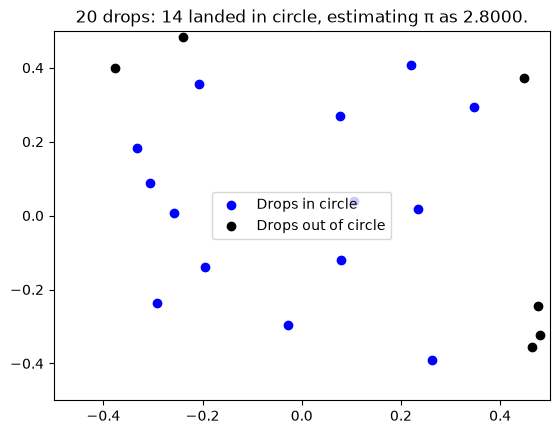

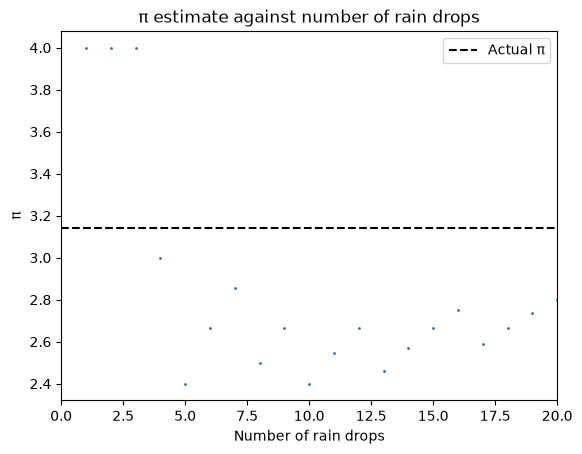

----------------------
20 drops
π estimated as: 2.800000
----------------------


In [1]:
from __future__ import division
from random import random
from math import pi
import matplotlib.pyplot as plt
import sys

def rain_drop(length_of_field=1):
    """
    Simulate a random rain drop within the field.
    """
    return [(.5 - random()) * length_of_field, (.5 - random()) * length_of_field]

def is_point_in_circle(point, length_of_field=1):
    """
    Check if a point lies within the inscribed circle.
    """
    return (point[0]) ** 2 + (point[1]) ** 2 <= (length_of_field / 2) ** 2

def plot_rain_drops(drops_in_circle, drops_out_of_circle, length_of_field=1, format='png'):
    """
    Plot the raindrops in and out of the circle.
    """
    plt.figure()
    plt.xlim(-length_of_field / 2, length_of_field / 2)
    plt.ylim(-length_of_field / 2, length_of_field / 2)
    plt.scatter([e[0] for e in drops_in_circle], [e[1] for e in drops_in_circle], color='blue', label="Drops in circle")
    plt.scatter([e[0] for e in drops_out_of_circle], [e[1] for e in drops_out_of_circle], color='black', label="Drops out of circle")
    plt.legend(loc="center")
    plt.title(f"{len(drops_in_circle) + len(drops_out_of_circle)} drops: {len(drops_in_circle)} landed in circle, estimating π as {4 * len(drops_in_circle) / (len(drops_in_circle) + len(drops_out_of_circle)):.4f}.")
    plt.savefig(f"rain_drops.{format}")
    plt.show()

def plot_pi_estimates(pi_estimate, total_drops):
    """
    Plot the π estimates as a function of the number of drops.
    """
    plt.figure()
    plt.scatter(range(1, total_drops + 1), pi_estimate, s=1)
    plt.hlines(pi, 0, total_drops, color='black', linestyle='dashed', label="Actual π")
    plt.xlim(0, total_drops)
    plt.title("π estimate against number of rain drops")
    plt.xlabel("Number of rain drops")
    plt.ylabel("π")
    plt.legend()
    plt.savefig(f"pi_estimate_{total_drops}_drops.png")
    plt.show()

def rain(number_of_drops=1000, length_of_field=1, plot=True, dynamic=False):
    """
    Simulate raindrops to estimate π.
    """
    number_of_drops_in_circle = 0
    drops_in_circle = []
    drops_out_of_circle = []
    pi_estimate = []
    for k in range(number_of_drops):
        drop = rain_drop(length_of_field)
        if is_point_in_circle(drop, length_of_field):
            drops_in_circle.append(drop)
            number_of_drops_in_circle += 1
        else:
            drops_out_of_circle.append(drop)
        # Update π estimate
        pi_estimate.append(4 * number_of_drops_in_circle / (k + 1))
        # Optional dynamic plotting
        if dynamic:
            plot_rain_drops(drops_in_circle, drops_out_of_circle, length_of_field, format='png')
            
    # Final plots
    if plot and not dynamic:
        plot_rain_drops(drops_in_circle, drops_out_of_circle, length_of_field)
        plot_pi_estimates(pi_estimate, number_of_drops)
        
    return number_of_drops_in_circle, number_of_drops

if __name__ == "__main__":
    try:
        # Prompt user with fallback for automated/batch execution
        raw_input = input("Enter the number of drops (default 1000): ").strip()
        number_of_drops = int(raw_input) if raw_input else 1000
    except Exception:
        number_of_drops = 1000
        print("Using default: 1000 drops.")

    # Simulate raindrops
    result = rain(number_of_drops, plot=True, dynamic=False)
    print("----------------------")
    print(f"{number_of_drops} drops")
    print(f"π estimated as: {4 * result[0] / result[1]:.6f}")
    print("----------------------")


### Executing the 1 to 10 iteration task from the whiteboard:

In [2]:
# Task: 1 to 10 iterations, randomly choose 10000 drops, calculate average value
iterations = 10
drops_per_iteration = 10000
estimated_pis = []

print(f"Running {iterations} iterations of {drops_per_iteration} drops each...")
for i in range(1, iterations + 1):
    # Run rain simulation without plotting for speed
    in_circle, total = rain(drops_per_iteration, plot=False)
    pi_val = 4 * in_circle / total
    estimated_pis.append(pi_val)
    print(f"Iteration {i}: Estimated Pi = {pi_val:.6f}")

average_pi = sum(estimated_pis) / len(estimated_pis)
print("\n----------------------")
print(f"Average estimated value of Pi over {iterations} iterations: {average_pi:.6f}")
print("----------------------")

Running 10 iterations of 10000 drops each...
Iteration 1: Estimated Pi = 3.146800
Iteration 2: Estimated Pi = 3.121600
Iteration 3: Estimated Pi = 3.108000
Iteration 4: Estimated Pi = 3.174800
Iteration 5: Estimated Pi = 3.145200
Iteration 6: Estimated Pi = 3.142800
Iteration 7: Estimated Pi = 3.143600
Iteration 8: Estimated Pi = 3.134800
Iteration 9: Estimated Pi = 3.156000
Iteration 10: Estimated Pi = 3.154400

----------------------
Average estimated value of Pi over 10 iterations: 3.142800
----------------------


## Discussion 
This Monte Carlo simulation approximates the value of π through the application of probability and
geometric proportions.
By sampling random coordinates (raindrops) on a square field and testing if these are located inside an
inscribed circle using the equality x² + y² ≤ r², we create a proportion of coordinates inside the
circle relative to the total number. Ideally, this should approximate to:

        π
      ─────
        4

As seen in the generated graphs and in the results of the 10-iteration experiment, the approximation
of π changes wildly for a low number of raindrops. But, according to the Law of Large Numbers,
when the number of random points increases (for example up to 10,000 drops), the resulting ratio
becomes more stable and converges towards the mathematical constant of π (π ≈3.14159).

Averaging the result across 10 iterations will further contribute to reducing the randomness of
results and will produce a more accurate final estimation. Although this method gives a visually
appealing and intuitively simple approach to estimate π, it consumes more computational power and
converges more slowly than analytical infinite series, such as the Leibniz formula or Wallis
product.



## Conclusion
This laboratory has been able to prove the usefulness of the Monte Carlo technique in estimating
  the value of the irrational number π. In particular, the experiment has proven the probability
  theory between the area of the circle and the area of the box containing the circle. The graph
  shows clearly that an increase in the number of samples (raindrops) will increase the accuracy
  of the result.